In [1]:
from xenonnt_plot_style import XENONPlotStyle as xps
xps.use('xenonnt')

In [2]:
import os
import numpy as np
import matplotlib.pyplot as plt

from utils import read_rga_file, get_t0, get_integral, get_partial_pressure, get_kr_concentration

In [3]:
folder = '../../Documents/RGAData/PressurevsTime'
# folder = '../rga'

# filenames = [
#     'PressurevsTime-20261102-171546-393.txt',
#     'PressurevsTime-20261106-100455-776.txt',
#     'PressurevsTime-20261106-103217-236.txt',
#     'PressurevsTime-20261106-114035-676.txt',
# ]

filenames = [
    'PressurevsTime-20261102-171546-393.txt',
    'PressurevsTime-20261113-171337-901.txt',
    'PressurevsTime-20261113-174008-024.txt',
]

masses = [87, 28, 40, 62, 84]

In [4]:
# Calibration inputs of each file, passed to get_kr_concentration
# TODO: fill in the measured values; all four are the defaults (notes/202611.tex) for now
calibrations = [
    dict(delta_v=0.0842, n_expansion=2, temperature=292, recycler_pressure=14.8),
    dict(delta_v=0.0100, n_expansion=2, temperature=292, recycler_pressure=14.8),
    dict(delta_v=0.0100, n_expansion=2, temperature=292, recycler_pressure=14.8),
]

t0_ranges = [
    (480, 780),
    (480, 780),
    (420, 720),
]

In [5]:
# Sample partial pressure of AMU 84 (Sec. 1) and Kr mole fraction (Sec. 2) of each file
P, P_err = np.empty(len(filenames)), np.empty(len(filenames))
x_kr, x_kr_err = np.empty(len(filenames)), np.empty(len(filenames))

for i, (filename, calibration, t0_range) in enumerate(zip(filenames, calibrations, t0_ranges)):
    rga = read_rga_file(os.path.join(folder, filename))
    t0 = get_t0(rga['t'], rga[28], t0_range=t0_range)
    P[i], P_err[i] = get_partial_pressure(rga, t0, mass=84)
    x_kr[i], x_kr_err[i] = get_kr_concentration(**calibration)

    print(
        f'{filename}: x_Kr = {x_kr[i] * 1e15:.0f} +- {x_kr_err[i] * 1e15:.0f} ppq, '
        f'P_sample = {P[i]:.3e} +- {P_err[i]:.1e} Torr'
    )

PressurevsTime-20261102-171546-393.txt: x_Kr = 951 +- 53 ppq, P_sample = 7.289e-11 +- 8.0e-13 Torr
PressurevsTime-20261113-171337-901.txt: x_Kr = 113 +- 6 ppq, P_sample = 3.766e-11 +- 3.8e-13 Torr
PressurevsTime-20261113-174008-024.txt: x_Kr = 113 +- 6 ppq, P_sample = 3.030e-11 +- 1.1e-12 Torr


P_sample = 4.644e-14 Torr/ppq * x_Kr + 2.873e-11 Torr


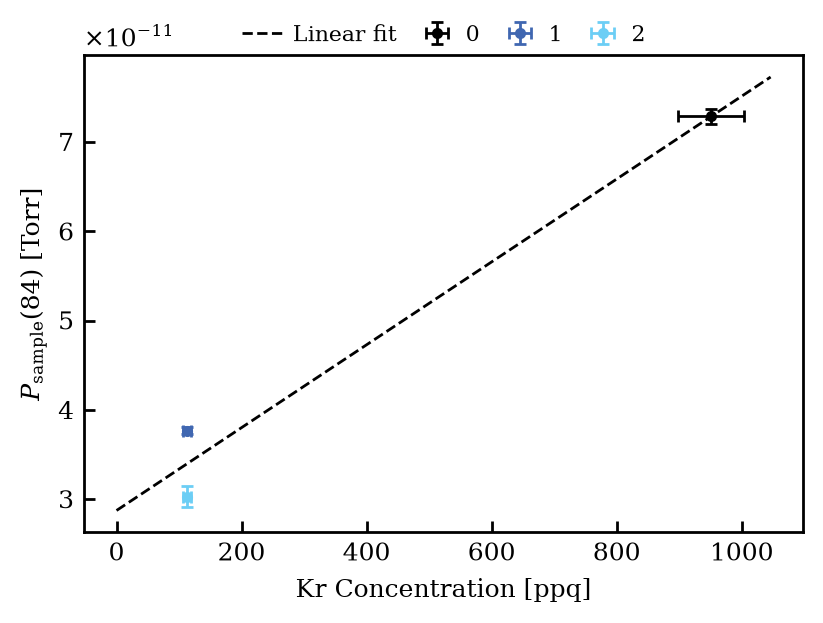

In [6]:
fig, ax = plt.subplots(1, 1, figsize=(4, 3))

for i in range(len(filenames)):
    ax.errorbar(
        x_kr[i] * 1e15, P[i],
        xerr=x_kr_err[i] * 1e15, yerr=P_err[i],
        marker='o', linestyle='none', capsize=2, label=i,
    )
# ax.plot(0, 0)

# Linear fit of P_sample against x_Kr, unweighted (uncertainties not used)
slope, intercept = np.polyfit(x_kr * 1e15, P, 1)
x_fit = np.linspace(0, 1.1 * np.max(x_kr * 1e15), 100)
ax.plot(x_fit, slope * x_fit + intercept, color='k', linestyle='--', label='Linear fit')
print(f'P_sample = {slope:.3e} Torr/ppq * x_Kr + {intercept:.3e} Torr')

ax.legend(ncols=len(filenames) + 1)
ax.set_xlabel('Kr Concentration [ppq]')
ax.set_ylabel('$P_\\mathrm{sample}$(84) [Torr]')

plt.show()